# 04 · EDA de relaciones (niveles 2–3, parte A): etiquetas, línea base HT0, HT2 y regímenes HT3

**Objetivo.** Construir el panel de modelado (ticker × semana, solo datos ≤ t), decidir los parámetros (k, N) de la etiqueta de triple barrera, calibrar la línea base GBM (HT0), medir la asociación indicador → etiqueta (HT2), decidir qué indicadores se conservan (E2) y revisar si la relación es estable entre regímenes (HT3).

**Punto del enunciado:** 6 (EDA bivariado y multivariado, niveles 2–3). **Hipótesis:** HT0, HT1 (preparada: la línea base y las etiquetas que usará el SVM), HT2, HT3 y HT4 (barreras escaladas por σ).

**Entradas (instantánea):** `precios_semanales` (ajustado por splits y dividendos). **Salidas:** figuras en `entregables/entrega_1/assets` y el panel con las decisiones de (k, N) e indicadores.

**Nota metodológica.** Las observaciones semanales de un mismo ticker no son independientes (las ventanas de N semanas se solapan y las etiquetas se autocorrelacionan). Por eso los p-valores de Mann-Whitney son descriptivos y los intervalos se obtienen con *block bootstrap*. El lenguaje es de asociación, no causal.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from asistente import config, datos, edgar, fundamentales as fu, damodaran as dm, indicadores as ind, etiquetas as et, riesgo as rg, simulacion as sim
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
config.DIR_ASSETS.mkdir(parents=True, exist_ok=True)

## 1. Panel de modelado
Una fila por ticker × semana. Los indicadores y σ (EWMA λ=0.94, conocida en t) usan solo datos ≤ t; las etiquetas miran hacia adelante y las últimas N semanas quedan censuradas (NaN). Se añade la etiqueta de retorno a 12 semanas, absoluta y relativa al ETF del sector.

In [2]:
sem = datos.cargar_snapshot("precios_semanales").sort_values(["ticker", "fecha"])
cl = sem.pivot(index="fecha", columns="ticker", values="close")
filas = []
for t in config.tickers():
    d = sem[sem.ticker == t].set_index("fecha")
    r = rg.log_retornos(d.close); sigma = rg.vol_ewma(r, 0.94, periodos=1)
    X = ind.tabla_indicadores(d.close, d.volume)
    for k in (1, 2):
        for n in (4, 12, 26):
            X[f"y_k{k}_n{n}"] = et.etiqueta_entrada(d.close, sigma, k_inf=k, k_sup=k, n=n).etiqueta
    etf = cl[config.ETF_SECTOR[config.industria_de(t)]]
    X["yret_abs12"] = et.etiqueta_retorno(d.close, 12)
    X["yret_rel12"] = et.etiqueta_retorno(d.close, 12, benchmark=etf)
    X["sigma"] = sigma; X["ticker"] = t; X["industria"] = config.industria_de(t)
    filas.append(X)
panel = pd.concat(filas).reset_index()
print(panel.shape, panel.fecha.min().date(), panel.fecha.max().date(), panel.ticker.nunique(), "tickers")
print(panel.isna().mean().round(3).to_dict())

(27326, 19) 2009-01-05 2026-10-12 30 tickers
{'fecha': 0.0, 'rsi14': 0.015, 'dist_sma20': 0.021, 'dist_sma50': 0.054, 'dist_ema20': 0.021, 'vol_rel20': 0.021, 'donchian20': 0.021, 'mom_12_1': 0.057, 'y_k1_n4': 0.005, 'y_k1_n12': 0.014, 'y_k1_n26': 0.03, 'y_k2_n4': 0.005, 'y_k2_n12': 0.014, 'y_k2_n26': 0.03, 'yret_abs12': 0.013, 'yret_rel12': 0.013, 'sigma': 0.001, 'ticker': 0.0, 'industria': 0.0}


## 2. Etiquetas: decisión de k y N
Para cada (k, N) se resume el balance de clases, las observaciones resueltas y censuradas, las ventanas no solapadas (`n_resueltas / N`, una cota de la muestra efectiva) y la ACF de la etiqueta en el rezago 1 (promedio por ticker; una ACF alta indica solapamiento entre ventanas vecinas).

In [3]:
def acf1(s):
    s = s.dropna()
    return s.autocorr(1) if len(s) > 30 else np.nan
filas = []
for k in (1, 2):
    for n in (4, 12, 26):
        c = f"y_k{k}_n{n}"; res = panel[c].notna()
        a = panel.groupby("ticker")[c].apply(acf1).mean()
        filas.append(dict(k=k, N=n, pct_clase1=panel[c].mean(), n_resueltas=int(res.sum()),
                          n_censuradas=int(panel[c].isna().sum()), n_no_solapadas=res.sum() / n, acf1_media=a))
tab_et = pd.DataFrame(filas); print(tab_et.to_string(index=False))
print("\nPor ticker (k=1, N=12): % clase 1 min/mediana/max:",
      panel.groupby("ticker")["y_k1_n12"].mean().agg(["min", "median", "max"]).round(3).to_dict())
bal = pd.DataFrame({"retorno_abs_12": panel.yret_abs12.agg(["mean", "count"]),
                    "retorno_rel_ETF_12": panel.yret_rel12.agg(["mean", "count"])}).T
bal.columns = ["pct_clase1", "n"]; print("\nEtiquetas de retorno a 12 semanas:\n", bal)

 k  N  pct_clase1  n_resueltas  n_censuradas  n_no_solapadas  acf1_media
 1  4      0.1649        27176           150       6794.0000      0.5441
 1 12      0.1711        26936           390       2244.6667      0.7345
 1 26      0.1704        26516           810       1019.8462      0.8137
 2  4      0.0341        27176           150       6794.0000      0.5134
 2 12      0.0388        26936           390       2244.6667      0.7505
 2 26      0.0382        26516           810       1019.8462      0.7977

Por ticker (k=1, N=12): % clase 1 min/mediana/max: {'min': 0.101, 'median': 0.17, 'max': 0.302}

Etiquetas de retorno a 12 semanas:
                     pct_clase1          n
retorno_abs_12          0.6386 26966.0000
retorno_rel_ETF_12      0.5047 26966.0000


**Justificación (k, N).** Se elige **k = 1, N = 12**: con k = 1 la clase 1 es ≈17 % (suficiente para entrenar y evaluar), mientras con k = 2 cae a ≈3–4 % (muy pocos positivos por ticker); N = 12 deja ≈2 245 ventanas no solapadas, contra ≈1 020 de N = 26, y su ACF(1) (0.73) es menor que la de N = 26 (0.81). N = 4 tiene menos solapamiento (0.54) pero un horizonte de un mes, demasiado corto para un nivel de entrada. La etiqueta de retorno absoluto está desbalanceada hacia 1 (64 %, por la tendencia alcista de la muestra), mientras la relativa al ETF queda en ≈50 %; la etiqueta de triple barrera es la de interés porque describe el riesgo de entrada (HT1), no solo el signo.

**Lectura:** la tabla anterior muestra que la clase 1 ronda 17 % para k = 1 en los tres horizontes y 3–4 % para k = 2; la ACF(1) de la etiqueta crece con N (0.54, 0.73, 0.81 para k = 1) porque las ventanas vecinas comparten semanas, por lo que el tamaño de muestra efectivo es cercano al de ventanas no solapadas y no al de filas.

## 3. HT0: línea base GBM frente a la tasa empírica
Se compara, para cada (k, N), la probabilidad GBM incondicional de la etiqueta (sin deriva, `prob_triple_barrera_gbm`) con la tasa observada. La base se calcula con la σ mediana de cada **decil de σ** (10 000 trayectorias), no con una σ global.

In [4]:
panel["dec_sigma"] = pd.qcut(panel.sigma, 10, labels=False)  # deciles sobre todo el panel
cal = []
for k in (1, 2):
    for n in (4, 12, 26):
        c = f"y_k{k}_n{n}"; sub = panel[panel[c].notna()]
        glob_ = sim.prob_triple_barrera_gbm(sub.sigma.median(), k, k, n, n_sims=10000)
        cal.append(dict(k=k, N=n, dec="global", sigma_med=sub.sigma.median(), gbm=glob_, emp=sub[c].mean()))
        for d, g in sub.groupby("dec_sigma"):
            cal.append(dict(k=k, N=n, dec=int(d), sigma_med=g.sigma.median(),
                            gbm=sim.prob_triple_barrera_gbm(g.sigma.median(), k, k, n, n_sims=10000), emp=g[c].mean(), n=len(g)))
cal = pd.DataFrame(cal); cal["brecha_pp"] = 100 * (cal.emp - cal.gbm)
print(cal[cal.dec == "global"].drop(columns=["dec", "n"]).to_string(index=False))
dd = cal[cal.dec != "global"]
print("\nBrecha por decil (pp): media, mín, máx por (k,N)\n", dd.groupby(["k", "N"]).brecha_pp.agg(["mean", "min", "max"]))
print("\nk=1, N=12 por decil de σ:\n", dd[(dd.k == 1) & (dd.N == 12)][["dec", "sigma_med", "gbm", "emp", "brecha_pp", "n"]].to_string(index=False))

 k  N  sigma_med    gbm    emp  brecha_pp
 1  4     0.0332 0.2156 0.1649    -5.0712
 1 12     0.0332 0.2740 0.1711   -10.2928
 1 26     0.0331 0.2914 0.1704   -12.1012
 2  4     0.0332 0.0310 0.0341     0.3111
 2 12     0.0332 0.0359 0.0388     0.2933
 2 26     0.0331 0.0423 0.0382    -0.4059

Brecha por decil (pp): media, mín, máx por (k,N)
          mean      min     max
k N                           
1 4   -5.1958 -13.3163  0.1988
  12 -10.4622 -21.5076 -5.0295
  26 -12.4095 -25.5644 -5.8432
2 4    0.2692  -2.1359  2.5739
  12   0.2427  -3.6071  2.1778
  26  -0.5226  -4.7455  2.7997

k=1, N=12 por decil de σ:
 dec  sigma_med    gbm    emp  brecha_pp         n
  0     0.0180 0.2656 0.2063    -5.9286 2724.0000
  1     0.0218 0.2679 0.1805    -8.7355 2714.0000
  2     0.0251 0.2694 0.1902    -7.9154 2686.0000
  3     0.0282 0.2709 0.2206    -5.0295 2679.0000
  4     0.0314 0.2730 0.2131    -5.9891 2670.0000
  5     0.0349 0.2755 0.1738   -10.1716 2693.0000
  6     0.0388 0.2769 0.1828 

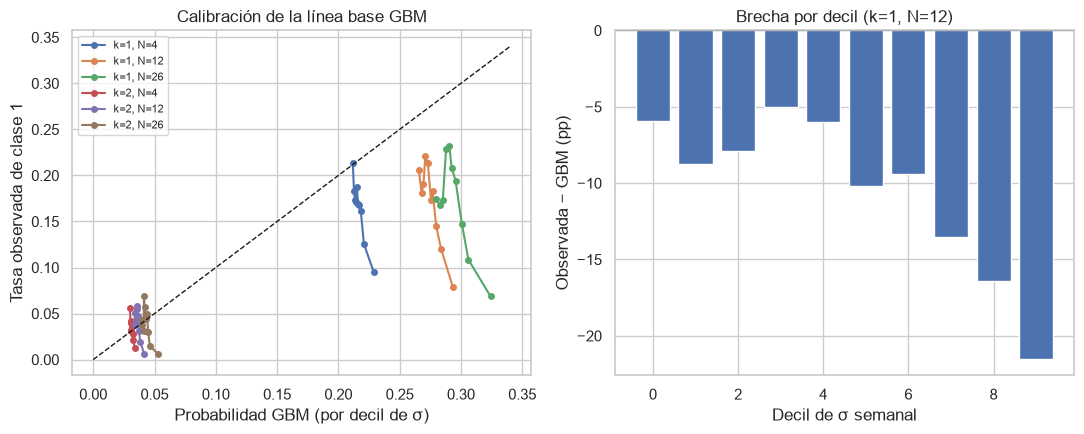

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for (k, n), g in dd.groupby(["k", "N"]):
    ax[0].plot(g.gbm, g.emp, "o-", ms=4, label=f"k={k}, N={n}")
lim = [0, dd[["gbm", "emp"]].max().max() * 1.05]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(xlabel="Probabilidad GBM (por decil de σ)", ylabel="Tasa observada de clase 1", title="Calibración de la línea base GBM")
ax[0].legend(fontsize=8)
g = dd[(dd.k == 1) & (dd.N == 12)]; ax[1].bar(g.dec, g.brecha_pp, color="C0")
ax[1].axhline(0, color="k", lw=.8); ax[1].set(xlabel="Decil de σ semanal", ylabel="Observada − GBM (pp)", title="Brecha por decil (k=1, N=12)")
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "nb04_calibracion_gbm.png", dpi=150, bbox_inches="tight"); plt.show()

**Lectura:** con k = 1 y N = 12 el GBM asigna 27.4 % a la clase 1 y la tasa observada es 17.1 %, una brecha de −10.3 pp; la brecha crece con el horizonte (−5.1 pp para N = 4, −12.1 pp para N = 26). Por deciles de σ (N = 12) va de −5.0 pp a −21.5 pp: el GBM sobreestima más cuando σ es alta (decil 10: GBM 29.4 % vs. 7.8 % observado). Con k = 2 la línea base casi coincide (brechas medias de +0.3 pp para N = 4 y 12). La asociación es compatible con que la volatilidad alta revierte (la barrera, ancha por σₜ, se toca menos) y con la deriva positiva de la muestra, ambas ignoradas por un GBM de σ constante y μ = 0.

**Justificación (HT0).** La caminata aleatoria sin deriva sirve como línea base a vencer, pero **no está calibrada** para k = 1: el SVM (HT1) debe compararse con el GBM *y* con la tasa empírica por decil de σ, o la mejora medida incluiría solo la corrección de este sesgo. En la práctica, σ y la tasa base por régimen de volatilidad serán rasgos del modelo. Esto refina la conclusión de 03 (HT0 apoyada, con dependencia lineal pequeña): la dirección es difícil de predecir, pero la *probabilidad* de tocar la barrera sí se aparta de la que implica un GBM.

**Síntesis (secciones 1–3).**
- Panel de 27 326 filas (30 tickers, 2009–2026); la muestra empieza en enero de 2009, así que la crisis 2008–09 queda cubierta solo desde su tramo final.
- Decisión: etiqueta de triple barrera con **k = 1, N = 12** (17 % de clase 1, ≈2 245 ventanas no solapadas).
- La línea base GBM sobreestima la clase 1 en 10 pp para k = 1 y N = 12 (hasta 21 pp en σ alta); alimenta HT1: comparar contra GBM y contra la tasa empírica por decil de σ.

## 4. HT2: indicadores frente a la etiqueta (k = 1, N = 12)
Se analizan los 7 indicadores contra `y_k1_n12` (1 = el precio toca primero la barrera inferior). Se reportan la distribución por clase, la AUC univariada (probabilidad de que un indicador mayor corresponda a la clase 1; 0.5 = sin asociación) con IC 95 % por *block bootstrap* (bloques contiguos de N = 12 semanas por ticker, 500 réplicas), la información mutua y Mann-Whitney (descriptivo: las observaciones no son independientes).

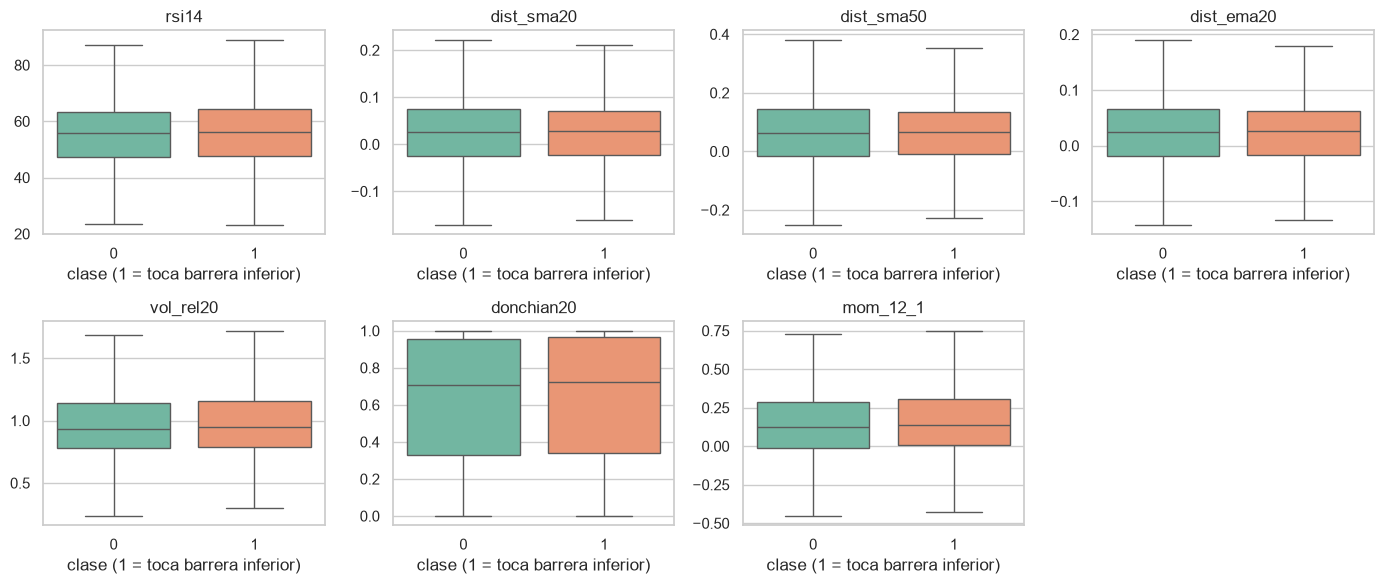

y_k1_n12    mediana clase 0  mediana clase 1
rsi14               55.7600          56.1931
dist_sma20           0.0258           0.0276
dist_sma50           0.0631           0.0648
dist_ema20           0.0254           0.0260
vol_rel20            0.9342           0.9488
donchian20           0.7047           0.7247
mom_12_1             0.1265           0.1401
n = 25406 | % clase 1 = 0.1781


In [6]:
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
IND = ["rsi14", "dist_sma20", "dist_sma50", "dist_ema20", "vol_rel20", "donchian20", "mom_12_1"]
Y = "y_k1_n12"
D = panel.dropna(subset=IND + [Y]).reset_index(drop=True)
fig, axs = plt.subplots(2, 4, figsize=(14, 6)); axs = axs.ravel()
for a, c in zip(axs, IND):
    lo, hi = D[c].quantile([.01, .99])
    sns.boxplot(data=D.assign(clase=D[Y].astype(int)), x="clase", y=c, ax=a, showfliers=False, palette="Set2", hue="clase", legend=False)
    a.set(title=c, xlabel="clase (1 = toca barrera inferior)", ylabel="")
axs[-1].axis("off"); fig.tight_layout()
fig.savefig(config.DIR_ASSETS / "nb04_boxplots_indicadores.png", dpi=150, bbox_inches="tight"); plt.show()
print(D.groupby(Y)[IND].median().T.rename(columns={0.0: "mediana clase 0", 1.0: "mediana clase 1"}))
print("n =", len(D), "| % clase 1 =", round(D[Y].mean(), 4))

**Lectura:** las medianas por clase son casi idénticas (p. ej., RSI 55.8 en la clase 0 y 56.2 en la clase 1; distancia a la SMA20 2.58 % vs. 2.76 %), de modo que los boxplots se superponen casi por completo. La clase 1 tiene un volumen relativo y un momentum algo mayores (0.949 vs. 0.934 y 13.99 % vs. 12.65 %), y el techo de Donchian es ligeramente más alto (0.725 vs. 0.705), una dirección coherente con la sobreextensión solo de forma tenue.

In [7]:
N, REPS = 12, 500
rng = np.random.default_rng(42)
grupos = [g.index.to_numpy() for _, g in D.groupby("ticker")]
y = D[Y].to_numpy(); Xv = D[IND].to_numpy()
def remuestra():
    idx = []
    for g in grupos:
        nb_ = int(np.ceil(len(g) / N)); ini = rng.integers(0, len(g) - N + 1, nb_)
        idx.append(g[(ini[:, None] + np.arange(N)).ravel()[:len(g)]])
    return np.concatenate(idx)
auc0 = np.array([roc_auc_score(y, Xv[:, j]) for j in range(len(IND))])
boot = np.empty((REPS, len(IND)))
for b in range(REPS):
    ix = remuestra(); boot[b] = [roc_auc_score(y[ix], Xv[ix, j]) for j in range(len(IND))]
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
mi = mutual_info_classif(Xv, y, n_neighbors=5, random_state=0)
mw = [stats.mannwhitneyu(Xv[y == 1, j], Xv[y == 0, j]).pvalue for j in range(len(IND))]
tab_auc = pd.DataFrame({"indicador": IND, "AUC": auc0, "IC95_inf": lo, "IC95_sup": hi,
                        "excluye_0.5": (lo > .5) | (hi < .5), "info_mutua": mi, "p_MW (descriptivo)": mw}).set_index("indicador")
print(f"Block bootstrap: {REPS} réplicas, bloques de {N} semanas por ticker")
print(tab_auc.assign(**{"p_MW (descriptivo)": tab_auc["p_MW (descriptivo)"].map("{:.2e}".format)}))

Block bootstrap: 500 réplicas, bloques de 12 semanas por ticker
              AUC  IC95_inf  IC95_sup  excluye_0.5  info_mutua  \
indicador                                                        
rsi14      0.5126    0.4915    0.5316        False      0.0000   
dist_sma20 0.4986    0.4786    0.5162        False      0.0026   
dist_sma50 0.4964    0.4781    0.5166        False      0.0041   
dist_ema20 0.4964    0.4772    0.5145        False      0.0026   
vol_rel20  0.5137    0.5022    0.5270         True      0.0006   
donchian20 0.5072    0.4866    0.5242        False      0.0000   
mom_12_1   0.5130    0.4943    0.5351        False      0.0064   

           p_MW (descriptivo)  
indicador                      
rsi14                7.65e-03  
dist_sma20           7.64e-01  
dist_sma50           4.42e-01  
dist_ema20           4.44e-01  
vol_rel20            3.77e-03  
donchian20           1.27e-01  
mom_12_1             5.87e-03  


**Lectura:** las AUC univariadas están entre 0.496 y 0.514; solo `vol_rel20` (0.5137, IC 95 % 0.502–0.527) tiene un IC que excluye 0.5, y por margen mínimo. RSI (0.5126), momentum (0.5130) y Donchian (0.5072) apuntan en el sentido de la sobreextensión (valores altos con más retrocesos de entrada) pero sus IC incluyen 0.5; las distancias a medias móviles están en 0.496–0.499. La información mutua es ≤ 0.0064 nats para todos (máx. `mom_12_1`). Mann-Whitney da p pequeños para RSI, `vol_rel20` y momentum (0.004–0.008), pero ese p-valor es descriptivo: las ventanas solapadas de un mismo ticker no son independientes y el IC por block bootstrap es el criterio.

**Justificación (HT2).** La evidencia **no apoya con fuerza** HT2: la asociación univariada indicador–etiqueta existe en el signo esperado para RSI, Donchian y momentum, pero es de ≈1 punto de AUC y solo un IC excluye 0.5. Se concluye "apoyo débil/parcial": ningún indicador solo discrimina, y el valor, si existe, estaría en combinaciones y en la interacción con σ (HT1). Es una asociación, no una relación causal ni una señal operable por sí sola. La AUC es agregada sobre tickers con tasas base distintas (10–30 %), lo que puede mezclar efectos entre tickers.

## 5. Redundancia e inclusión/exclusión (E2)

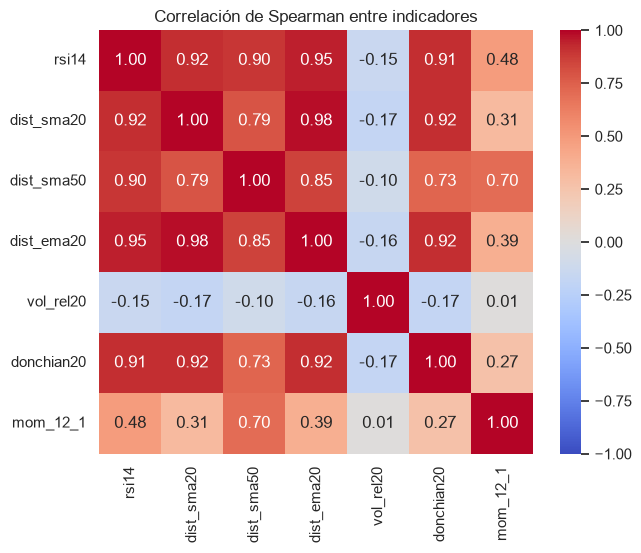

VIF (7 indicadores):
 {'rsi14': 11.24, 'dist_sma20': 35.13, 'dist_sma50': 15.76, 'dist_ema20': 55.56, 'vol_rel20': 1.06, 'donchian20': 6.55, 'mom_12_1': 3.54}
Pares con |ρ| > 0.7:
 dist_sma20  dist_ema20   0.9780
rsi14       dist_ema20   0.9460
dist_sma20  donchian20   0.9200
rsi14       dist_sma20   0.9170
dist_ema20  donchian20   0.9160
rsi14       donchian20   0.9140
            dist_sma50   0.8950
dist_sma50  dist_ema20   0.8540
dist_sma20  dist_sma50   0.7890
dist_sma50  donchian20   0.7330
            mom_12_1     0.7020
dtype: float64


In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
C = D[IND].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5)); sns.heatmap(C, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman entre indicadores"); fig.savefig(config.DIR_ASSETS / "nb04_spearman_indicadores.png", dpi=150, bbox_inches="tight"); plt.show()
def tabla_vif(cols):
    Z = sm.add_constant((D[cols] - D[cols].mean()) / D[cols].std())
    return pd.Series([variance_inflation_factor(Z.values, i + 1) for i in range(len(cols))], index=cols)
print("VIF (7 indicadores):\n", tabla_vif(IND).round(2).to_dict())
pares = C.where(np.triu(np.ones(C.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("Pares con |ρ| > 0.7:\n", pares[pares.abs() > .7].round(3))

In [9]:
sel = list(IND); pasos = []
while True:
    v = tabla_vif(sel)
    if v.max() < 10: break
    q = v.idxmax(); pasos.append((q, float(round(v[q], 1)), float(round(C.loc[q, [c for c in sel if c != q]].abs().max(), 3))))
    sel.remove(q)
print("Exclusiones sucesivas (indicador, VIF, |ρ| máx. con los restantes):", pasos)
print("Conservados:", sel, "\nVIF finales:", tabla_vif(sel).round(2).to_dict())
print("AUC de los excluidos vs. conservados:\n", tab_auc.loc[IND, ["AUC", "info_mutua"]].assign(conservado=[c in sel for c in IND]))

Exclusiones sucesivas (indicador, VIF, |ρ| máx. con los restantes): [('dist_ema20', 55.6, 0.978), ('dist_sma50', 11.6, 0.895)]
Conservados: ['rsi14', 'dist_sma20', 'vol_rel20', 'donchian20', 'mom_12_1'] 
VIF finales: {'rsi14': 8.41, 'dist_sma20': 4.32, 'vol_rel20': 1.05, 'donchian20': 5.85, 'mom_12_1': 1.38}
AUC de los excluidos vs. conservados:
               AUC  info_mutua  conservado
indicador                                
rsi14      0.5126      0.0000        True
dist_sma20 0.4986      0.0026        True
dist_sma50 0.4964      0.0041       False
dist_ema20 0.4964      0.0026       False
vol_rel20  0.5137      0.0006        True
donchian20 0.5072      0.0000        True
mom_12_1   0.5130      0.0064        True


**Justificación (exclusiones).** Se excluyen de forma sucesiva los indicadores con VIF ≥ 10 (estandarizados): **`dist_ema20`** (VIF 55.6; ρ = 0.978 con `dist_sma20`, que es casi la misma información: la EMA20 es una media de 20 semanas con otro peso) y **`dist_sma50`** (VIF 11.6 tras la primera exclusión; ρ = 0.895 con RSI14 y 0.789 con `dist_sma20`). Entre `dist_sma20` y `dist_ema20` se conserva la SMA por ser más simple y tener la AUC no inferior (0.4986 vs. 0.4964); `dist_sma50` aporta una AUC (0.4964) y una información mutua (0.0041) que no compensan su colinealidad. Quedan 5 indicadores (`rsi14`, `dist_sma20`, `vol_rel20`, `donchian20`, `mom_12_1`) con VIF máx. 8.4 (RSI) y 5.9 (Donchian). La redundancia es entre las variables de nivel de precio (RSI, distancias y Donchian, con ρ de 0.91–0.95 entre sí); `vol_rel20` (VIF 1.05) y `mom_12_1` (1.38) son prácticamente independientes del resto. Esta selección es para la interpretación y el SVM; la regularización del modelo puede tolerar algo de colinealidad.

**Síntesis (secciones 4–5).**
- HT2: asociación débil; solo `vol_rel20` tiene un IC de la AUC que excluye 0.5 (0.5137, 0.502–0.527); RSI, momentum y Donchian apuntan en el sentido esperado sin significancia por block bootstrap; la información mutua es ≤ 0.0064.
- E2: 5 indicadores conservados (se excluyen `dist_ema20` y `dist_sma50` por VIF y por ρ); alimenta las características del SVM (Tarea de modelado).
- Expectativa para HT1: un modelo con estos rasgos solo mejoraría la línea base por interacciones o por σ; se medirá con AUC/Brier walk-forward.

## 6. HT3: estabilidad por régimen de mercado
Los regímenes se justifican con los drawdowns del SPY (calculados sobre el cierre semanal ajustado).

In [10]:
spy = cl["SPY"].dropna(); dd_spy = spy / spy.cummax() - 1
cortes = dd_spy[dd_spy < -0.15].index
grupos_ep = np.split(cortes, np.where(np.diff(cortes.values).astype("timedelta64[D]") > np.timedelta64(120, "D"))[0] + 1)
for g in grupos_ep:
    valle = dd_spy.loc[g].idxmin(); pico = spy.loc[:valle].idxmax()
    print(f"Pico {pico.date()}  valle {valle.date()}  profundidad {dd_spy[valle]:.1%}")
print("Primer dato SPY:", spy.index[0].date(), "| drawdown inicial:", f"{dd_spy.iloc[0]:.1%}")
print("Máx. drawdown ene–jun 2009:", f"{dd_spy['2009-01':'2009-06'].min():.1%}", "| mar-2009 valle:", dd_spy['2009-01':'2009-06'].idxmin().date())
anual = spy.resample("YE").last().pct_change().dropna(); print("Retorno anual SPY:", (anual * 100).round(1).rename(lambda f: f.year).to_dict())

Pico 2009-01-05  valle 2009-03-02  profundidad -22.6%
Pico 2010-04-19  valle 2010-06-28  profundidad -15.7%
Pico 2011-04-25  valle 2011-08-15  profundidad -17.0%
Pico 2018-09-17  valle 2018-12-17  profundidad -17.1%
Pico 2020-02-10  valle 2020-03-16  profundidad -31.8%
Pico 2021-12-27  valle 2022-09-26  profundidad -23.9%
Pico 2025-02-10  valle 2025-03-31  profundidad -16.9%
Primer dato SPY: 2009-01-05 | drawdown inicial: 0.0%
Máx. drawdown ene–jun 2009: -22.6% | mar-2009 valle: 2009-03-02
Retorno anual SPY: {2010: 15.1, 2011: 1.9, 2012: 19.2, 2013: 27.5, 2014: 14.5, 2015: 1.3, 2016: 12.0, 2017: 21.7, 2018: -3.6, 2019: 30.2, 2020: 18.1, 2021: 28.7, 2022: -18.2, 2023: 26.2, 2024: 26.1, 2025: 16.8, 2026: 14.8}


**Lectura (drawdowns del SPY):** los episodios de caída > 15 % son: valle de marzo de 2009 (−22.6 % desde el primer dato de la muestra, enero de 2009, por lo que subestima la crisis 2007–09 completa), COVID (pico 2020-02-10, valle 2020-03-16, −31.8 %), el mercado bajista de 2022 (pico 2021-12-27, valle 2022-09-26, −23.9 %) y caídas menores (−15.7 % a −17.1 % en 2010, 2011, 2018 y 2025).

**Justificación (regímenes).** Se definen cinco regímenes según la fecha de entrada t: **Crisis 2009** (2009-01-05 a 2009-12-31: valle −22.6 % y rebote posterior; la muestra no incluye 2008); **Expansión** (2010-01-01 a 2020-01-31 y 2020-05-01 a 2021-12-26, con retornos anuales del SPY positivos salvo 2018: −3.6 %); **COVID** (2020-02-01 a 2020-04-30, el pico y valle de −31.8 %); **Bajista 2022** (2021-12-27 a 2022-12-31, −23.9 %); **Reciente** (desde 2023-01-01). Las fechas siguen los picos y valles anteriores, no se eligieron mirando la AUC.

In [11]:
REG = [("Crisis 2009", "2009-01-05", "2009-12-31"), ("Expansión", "2010-01-01", "2020-01-31"),
       ("COVID", "2020-02-01", "2020-04-30"), ("Expansión", "2020-05-01", "2021-12-26"),
       ("Bajista 2022", "2021-12-27", "2022-12-31"), ("Reciente", "2023-01-01", "2026-12-31")]
D2 = panel.dropna(subset=[Y]).reset_index(drop=True); D2["regimen"] = None
for nombre, a, b in REG:
    D2.loc[(D2.fecha >= a) & (D2.fecha <= b), "regimen"] = nombre
orden = ["Crisis 2009", "Expansión", "COVID", "Bajista 2022", "Reciente"]
bal_reg = D2.groupby("regimen")[Y].agg(n="count", pct_clase1="mean").loc[orden]
bal_reg["n_clase1"] = D2.groupby("regimen")[Y].sum().loc[orden].astype(int)
bal_reg["dd_SPY_max"] = [dd_spy[(dd_spy.index >= a) & (dd_spy.index <= b)].min() for a, b in
                         [("2009-01-05", "2009-12-31"), ("2010-01-01", "2021-12-26"), ("2020-02-01", "2020-04-30"), ("2021-12-27", "2022-12-31"), ("2023-01-01", "2026-12-31")]]
print(bal_reg)

                  n  pct_clase1  n_clase1  dd_SPY_max
regimen                                              
Crisis 2009    1428      0.0532        76     -0.2264
Expansión     17948      0.1577      2831     -0.3183
COVID           390      0.3692       144     -0.3183
Bajista 2022   1590      0.3346       532     -0.2393
Reciente       5580      0.1837      1025     -0.1743


**Lectura (balance de clases):** el porcentaje de clase 1 depende fuertemente del régimen: 5.3 % en Crisis 2009 (1 428 filas, 76 positivas), 15.8 % en Expansión (17 948), 36.9 % en COVID (390 filas) y 33.5 % en Bajista 2022 (1 590), contra 18.4 % en Reciente (5 580). La tasa base de la clase 1 se multiplica por más de 2 en los regímenes de caída; un modelo que ignore el régimen heredaría esa variación.

In [12]:
TOP3 = tab_auc.assign(d=(tab_auc.AUC - .5).abs()).sort_values("d", ascending=False).index[:3].tolist()
print("Top 3 por |AUC − 0.5|:", TOP3)
def auc_boot(sub, c, reps=200, sem_=7):
    """Block bootstrap por FECHA: bloques contiguos de semanas comunes a todos los tickers (conserva la dependencia transversal)."""
    r = np.random.default_rng(sem_); fechas = np.sort(sub.fecha.unique()); nd = len(fechas)
    L = 12 if nd >= 100 else 4; pos = {f: g.to_numpy() for f, g in sub.groupby("fecha").groups.items()}
    ys, xs = sub[Y].to_numpy(), sub[c].to_numpy(); a0 = roc_auc_score(ys, xs); bs = np.full(reps, np.nan)
    for b in range(reps):
        ini = r.integers(0, nd - L + 1, int(np.ceil(nd / L)))
        ix = np.concatenate([pos[f] for f in fechas[(ini[:, None] + np.arange(L)).ravel()[:nd]]])
        if 0 < ys[ix].sum() < len(ix): bs[b] = roc_auc_score(ys[ix], xs[ix])
    return a0, np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5), L
filas = []
for rg_ in orden:
    for c in TOP3:
        sub = D2[(D2.regimen == rg_) & D2[c].notna()].reset_index(drop=True)
        if len(sub) < 300: filas.append(dict(regimen=rg_, indicador=c, n=len(sub))); continue
        a0, l, h, L = auc_boot(sub, c)
        filas.append(dict(regimen=rg_, indicador=c, n=len(sub), AUC=a0, IC_inf=l, IC_sup=h, bloque=L, excluye_05=(l > .5) or (h < .5)))
tab_reg = pd.DataFrame(filas); print("Block bootstrap por fecha: 200 réplicas por régimen (bloques de 12 semanas; 4 si el régimen tiene < 100 semanas)")
print(tab_reg.pivot(index="regimen", columns="indicador", values="AUC").loc[orden])
print(tab_reg.to_string(index=False))

Top 3 por |AUC − 0.5|: ['vol_rel20', 'mom_12_1', 'rsi14']


Block bootstrap por fecha: 200 réplicas por régimen (bloques de 12 semanas; 4 si el régimen tiene < 100 semanas)
indicador     mom_12_1  rsi14  vol_rel20
regimen                                 
Crisis 2009        NaN 0.9505     0.4779
Expansión       0.5089 0.5189     0.5131
COVID           0.7875 0.7363     0.4641
Bajista 2022    0.6372 0.6505     0.4715
Reciente        0.4966 0.5130     0.5132
     regimen indicador     n    AUC  IC_inf  IC_sup  bloque excluye_05
 Crisis 2009 vol_rel20   924 0.4779  0.1674  0.6715  4.0000      False
 Crisis 2009  mom_12_1     0    NaN     NaN     NaN     NaN        NaN
 Crisis 2009     rsi14  1064 0.9505  0.9253  0.9813  4.0000       True
   Expansión vol_rel20 17912 0.5131  0.4762  0.5437 12.0000      False
   Expansión  mom_12_1 17846 0.5089  0.4599  0.5519 12.0000      False
   Expansión     rsi14 17922 0.5189  0.4677  0.5662 12.0000      False
       COVID vol_rel20   390 0.4641  0.2362  0.9600  4.0000      False
       COVID  mom_12_1   390 0.7

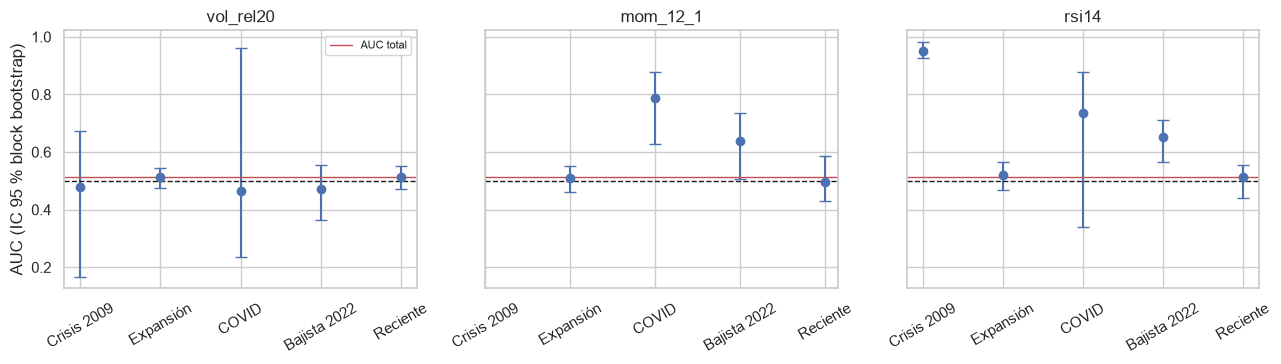

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, c in zip(ax, TOP3):
    g = tab_reg[tab_reg.indicador == c].set_index("regimen").loc[orden]
    a.errorbar(range(len(orden)), g.AUC, yerr=[(g.AUC - g.IC_inf).clip(lower=0), (g.IC_sup - g.AUC).clip(lower=0)], fmt="o", capsize=4)
    a.axhline(.5, color="k", ls="--", lw=1); a.axhline(tab_auc.loc[c, "AUC"], color="C3", lw=1, label="AUC total")
    a.set_xticks(range(len(orden))); a.set_xticklabels([o.replace(" (cola)", "") for o in orden], rotation=30); a.set_title(c)
ax[0].set_ylabel("AUC (IC 95 % block bootstrap)"); ax[0].legend(fontsize=8); fig.tight_layout()
fig.savefig(config.DIR_ASSETS / "nb04_auc_por_regimen.png", dpi=150, bbox_inches="tight"); plt.show()

**Lectura (AUC por régimen):** en Expansión y Reciente (≈ 87 % de las observaciones) las AUC de `vol_rel20`, `mom_12_1` y `rsi14` quedan en 0.497–0.519 con IC que incluyen 0.5, igual que en el total. En COVID y Bajista 2022 sube la AUC de `mom_12_1` (0.788 y 0.637) y `rsi14` (0.736 y 0.651), con IC de 0.629–0.877 (momentum, COVID) y 0.564–0.711 (RSI, 2022) que excluyen 0.5, y `vol_rel20` queda bajo 0.5 (0.464 y 0.472, IC que incluyen 0.5). En Crisis 2009, el RSI tiene una AUC de 0.951 (IC 0.925–0.981), pero solo con ≈ 36 semanas y 76 positivas porque los indicadores necesitan 14 a 52 semanas de arranque (`mom_12_1` no existe en 2009).

**Justificación (HT3).** La señal **no es estable entre regímenes**: es débil e indistinguible de 0.5 en el 87 % de la muestra y sube a 0.64–0.79 en caídas de mercado, donde indicadores como RSI y momentum altos preceden con más frecuencia caídas de al menos 1σ√N. Se interpreta con cautela, como asociación: en COVID y 2022 hay un único evento común a todos los tickers (los IC por bloques de fechas son anchos, p. ej. RSI en COVID 0.34–0.88) y la clase 1 es allí 2 veces más frecuente, de modo que la AUC mezcla la discriminación con el timing del evento. Decisión: HT3 se considera **no apoyada** en su forma fuerte (estabilidad), y se registra el régimen o la volatilidad del mercado como rasgo candidato y se evalúa el SVM walk-forward por régimen.

**Síntesis (sección 6).**
- Regímenes definidos con drawdowns del SPY (COVID −31.8 %, 2022 −23.9 %, 2009 −22.6 %); la muestra empieza en 2009.
- Clase 1: 5.3 % (2009), 15.8 % (expansión), 36.9 % (COVID), 33.5 % (2022), 18.4 % (reciente).
- La AUC de RSI y momentum pasa de ≈ 0.51 (expansión y reciente) a 0.64–0.79 (COVID y 2022); la relación no es estable. Alimenta la validación walk-forward por régimen (HT1).

## Nivel 3 (continúa)